# Wetteranalyse Berlin

Tageswerte für Berlin (2024) von der kostenlosen [Open-Meteo-Archiv-API](https://open-meteo.com/en/docs/historical-weather-api) (kein API-Key nötig, Internetzugang erforderlich).

**Ablauf**
1. Daten laden
2. Überblick und Kennzahlen
3. Monatliche Temperatur
4. Monatlicher Niederschlag
5. Extremwerte

In [1]:
import pandas as pd
import requests
import matplotlib.pyplot as plt

In [2]:
params = {
    'latitude': 52.52,
    'longitude': 13.41,
    'start_date': '2024-01-01',
    'end_date': '2024-12-31',
    'daily': 'temperature_2m_max,temperature_2m_min,temperature_2m_mean,precipitation_sum',
    'timezone': 'Europe/Berlin',
}
antwort = requests.get('https://archive-api.open-meteo.com/v1/archive', params=params, timeout=30)
antwort.raise_for_status()

df = pd.DataFrame(antwort.json()['daily'])
df['time'] = pd.to_datetime(df['time'])
df = df.rename(columns={
    'time': 'datum',
    'temperature_2m_max': 'temp_max',
    'temperature_2m_min': 'temp_min',
    'temperature_2m_mean': 'temp_mittel',
    'precipitation_sum': 'niederschlag_mm',
}).set_index('datum')
df.head()

,temp_max,temp_min,temp_mittel,niederschlag_mm
datum,,,,
2024-01-01,7.5,3.4,5.2,1.9
2024-01-02,7.9,2.4,4.5,8.5
2024-01-03,10.6,7.0,8.7,10.8
2024-01-04,7.3,-2.3,3.7,2.8
2024-01-05,0.9,-0.7,0.4,5.4


In [3]:
df.describe().round(1)

,temp_max,temp_min,temp_mittel,niederschlag_mm
count,366.0,366.0,366.0,366.0
mean,15.7,7.7,11.7,1.8
std,8.5,6.5,7.4,3.2
min,-3.9,-10.6,-7.9,0.0
25%,8.6,2.4,5.3,0.0
50%,15.4,8.1,11.4,0.2
75%,22.9,13.1,18.4,2.1
max,34.1,21.4,27.4,26.3


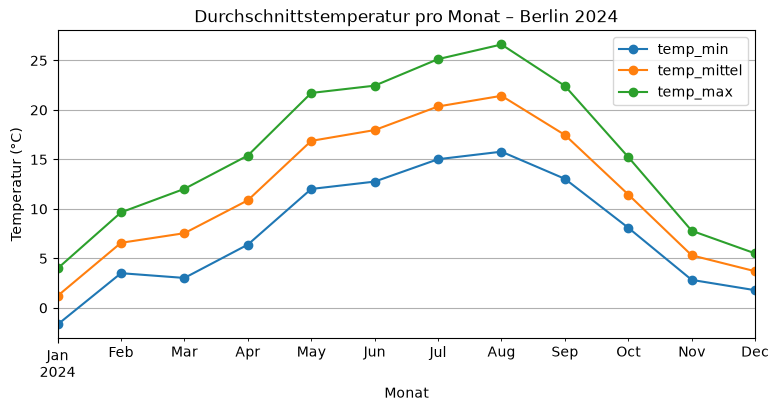

In [4]:
monat_temp = df[['temp_min', 'temp_mittel', 'temp_max']].resample('MS').mean()

ax = monat_temp.plot(figsize=(9, 4), marker='o')
ax.set_title('Durchschnittstemperatur pro Monat – Berlin 2024')
ax.set_xlabel('Monat')
ax.set_ylabel('Temperatur (°C)')
ax.grid(True)
plt.show()

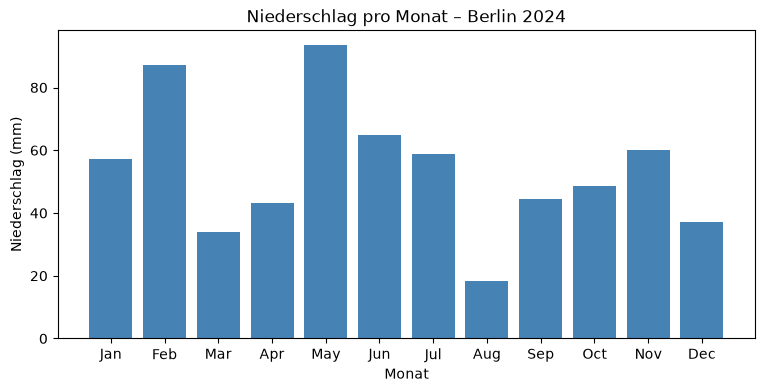

In [5]:
monat_regen = df['niederschlag_mm'].resample('MS').sum()

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(monat_regen.index.strftime('%b'), monat_regen.values, color='steelblue')
ax.set_title('Niederschlag pro Monat – Berlin 2024')
ax.set_xlabel('Monat')
ax.set_ylabel('Niederschlag (mm)')
plt.show()

In [6]:
print(f"Heißester Tag:   {df['temp_max'].idxmax():%d.%m.%Y} ({df['temp_max'].max():.1f} °C)")
print(f"Kältester Tag:   {df['temp_min'].idxmin():%d.%m.%Y} ({df['temp_min'].min():.1f} °C)")
print(f"Nassester Tag:   {df['niederschlag_mm'].idxmax():%d.%m.%Y} ({df['niederschlag_mm'].max():.1f} mm)")
print(f"Regentage (>=1 mm): {(df['niederschlag_mm'] >= 1).sum()}")
print(f"Sommertage (>=25 °C): {(df['temp_max'] >= 25).sum()}")
print(f"Frosttage (<0 °C):    {(df['temp_min'] < 0).sum()}")

Heißester Tag:   29.08.2024 (34.1 °C)
Kältester Tag:   09.01.2024 (-10.6 °C)
Nassester Tag:   19.11.2024 (26.3 mm)
Regentage (>=1 mm): 126
Sommertage (>=25 °C): 60
Frosttage (<0 °C):    44
